# `vkgeoviews` Demo — CRS-Aware Maps & GPU Choropleths

Combines **`vkgeoviews`** (`gv.Points`, `gv.Polygons`, `gv.tile_sources`) with **`vkspatial`** single-pass GPU `sjoin()` on **11.84M NYC Taxi trips** to render:
1. A **NYC Neighborhood Mean-Fare Choropleth** over `CartoDark` tiles.
2. **Datashaded GPU Pickups + Polygon Boundaries** over `EsriImagery` satellite tiles.
3. Automatic GPU `EPSG:4326` (lon/lat) → `EPSG:3857` (Web Mercator) projection.

In [1]:
import sys, time
from pathlib import Path
_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vkpandas as vpd
import vkspatial as vksp
import vkgeoviews as gv

taxi_path = Path.home() / ".cache/hvsampledata/nyc_taxi/v2/nyc_taxi_wide.parq"
df = vpd.read_parquet(taxi_path, columns=["pickup_x", "pickup_y", "fare_amount", "tip_amount"])
df = df[df["fare_amount"] > 0.0]

# NYC neighborhood polygons defined in standard WGS84 (lon, lat)
NYC_ZONES_LONLAT = {
    "Midtown":     [(-74.0020, 40.7484), (-73.9675, 40.7484), (-73.9610, 40.7685), (-73.9935, 40.7685)],
    "FiDi":        [(-74.0185, 40.7005), (-74.0010, 40.7015), (-74.0000, 40.7145), (-74.0165, 40.7155)],
    "SoHo / GV":   [(-74.0105, 40.7195), (-73.9905, 40.7195), (-73.9880, 40.7395), (-74.0095, 40.7395)],
    "Upper East":  [(-73.9735, 40.7645), (-73.9445, 40.7645), (-73.9410, 40.7855), (-73.9595, 40.7855)],
    "Upper West":  [(-73.9930, 40.7685), (-73.9735, 40.7685), (-73.9600, 40.7935), (-73.9825, 40.7935)],
}

# Project polygons to Web Mercator for single-pass GPU spatial join on all 11.84M trips
zones_merc = {}
for name, ring in NYC_ZONES_LONLAT.items():
    mx, my = vksp.lonlat_to_mercator(np.array([p[0] for p in ring], dtype=np.float32), np.array([p[1] for p in ring], dtype=np.float32))
    zones_merc[name] = np.column_stack([mx.to_numpy(), my.to_numpy()]).astype(np.float32)

t0 = time.perf_counter()
gdf = vksp.GeoDataFrame(df, x="pickup_x", y="pickup_y", crs="EPSG:3857")
joined = gdf.sjoin(zones_merc, zone_col="zone_id", how="inner")
sjoin_ms = (time.perf_counter() - t0) * 1000.0

zone_names = list(NYC_ZONES_LONLAT.keys())
by_zone = joined.df[["zone_id", "fare_amount", "tip_amount"]].groupby("zone_id").mean()
z_ids = by_zone["zone_id"].to_list()
z_fares = by_zone["fare_amount"].to_list()
mean_fares = {zone_names[int(zid)]: float(f) for zid, f in zip(z_ids, z_fares)}
print(f"Single-pass GPU sjoin on {len(df):,} trips -> {len(joined):,} matched in {sjoin_ms:.1f} ms")
for k, v in mean_fares.items():
    print(f"  {k:12s}: mean fare = ${v:.2f}")

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Single-pass GPU sjoin on 11,836,806 trips -> 7,918,710 matched in 634.3 ms
  Midtown     : mean fare = $9.82
  FiDi        : mean fare = $14.25
  SoHo / GV   : mean fare = $10.14
  Upper East  : mean fare = $9.71
  Upper West  : mean fare = $9.51


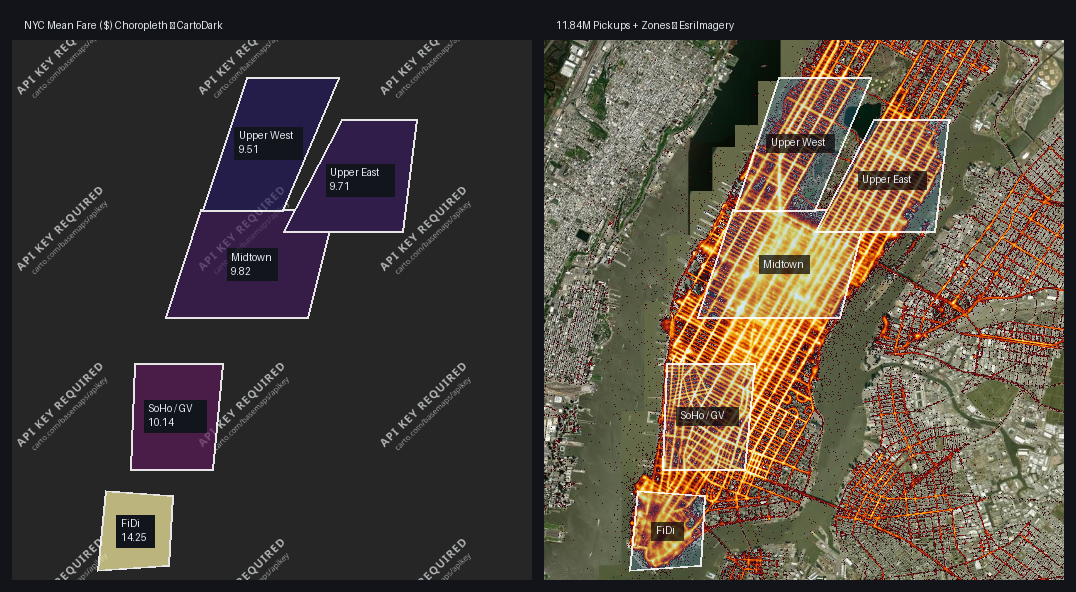

In [2]:
xr, yr = (-8242000, -8228000), (4968000, 4983000)

# 1. Choropleth map over CartoDark tiles (Polygons auto-projected from EPSG:4326 on GPU!)
choro = (
    gv.tile_sources.CartoDark
    * gv.Polygons(NYC_ZONES_LONLAT, values=mean_fares, crs="EPSG:4326", alpha=175)
).opts(width=520, height=540, xlim=xr, ylim=yr, title="NYC Mean Fare ($) Choropleth — CartoDark")

# 2. Datashaded 11.84M GPU pickups + neighborhood outlines over Esri Satellite
sat_combo = (
    gv.tile_sources.EsriImagery
    * gv.datashade(gv.Points(df, ["pickup_x", "pickup_y"], crs="EPSG:3857"), how="eq_hist")
    * gv.Polygons(NYC_ZONES_LONLAT, values=None, crs="EPSG:4326", alpha=45, show_labels=True)
).opts(width=520, height=540, xlim=xr, ylim=yr, title="11.84M Pickups + Zones — EsriImagery")

(choro + sat_combo).cols(2)